In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
dataset = pd.read_csv(r"C:\Users\acer\Downloads\customer_booking.csv",encoding="latin-1")
display(dataset.head())


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [2]:
#Clean Outliers
#Found outliersin prod_qty in transaction dataset which is has 600 as max value
#identified outliers and removed them
df = dataset.copy()
df = df[df['purchase_lead'] < 600]
print("Outliers in Transaction Dataset based on purchase lead:")
print(df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicated values in Transaction Dataset:")
print(df.duplicated().sum())


Outliers in Transaction Dataset based on purchase lead:
719
Duplicated values in Transaction Dataset:
0


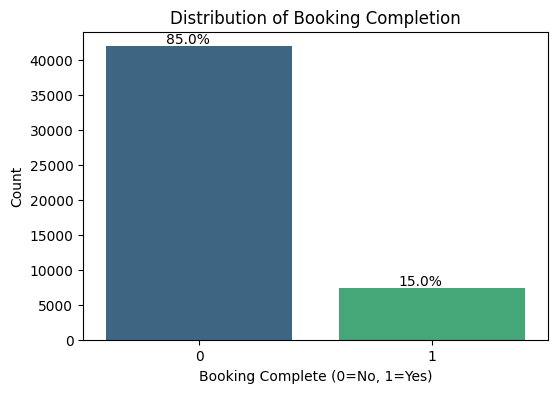

In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='booking_complete', palette='viridis')
plt.title('Distribution of Booking Completion')
plt.xlabel('Booking Complete (0=No, 1=Yes)')
plt.ylabel('Count')

# Add percentage labels
total = len(df)
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    x = p.get_x() + p.get_width() / 2 - 0.05
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.show()


In [4]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import pandas as pd

# Initialize tools
le = LabelEncoder()
encoders = {} # Dictionary to store encoder classes for inverse_transform later

# --- 1. Label Encoding (LE) ---
# Applied to high cardinality columns and 'flight_day' as requested.
# 'flight_day' is put here for backend simplicity (inverse transform capability).
le_columns = ['flight_day', 'route', 'booking_origin']

for col in le_columns:
    if col in df.columns:
        # Fit and transform the data
        df[col] = le.fit_transform(df[col])
        # Save the classes (e.g., Mon, Tue...) to the dictionary for backend use
        encoders[col] = le.classes_

# --- 2. One-Hot Encoding (OHE) ---
# Applied to low cardinality columns to prevent the model from assuming a false ranking order.
# e.g., 'Internet' is not mathematically "smaller" than 'Mobile'.
ohe_columns = ['sales_channel', 'trip_type']

# Apply One-Hot Encoding using pandas get_dummies
# drop_first=True is important to prevent multicollinearity (dummy variable trap)
df = pd.get_dummies(df, columns=ohe_columns, drop_first=True)

# Check the final dataframe structure
print("--- Data Preparation Complete ---")
print("Encoded Columns:")
print(df.columns.tolist())
display(df.head())


--- Data Preparation Complete ---
Encoded Columns:
['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'flight_day', 'route', 'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration', 'booking_complete', 'sales_channel_Mobile', 'trip_type_OneWay', 'trip_type_RoundTrip']


,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,sales_channel_Mobile,trip_type_OneWay,trip_type_RoundTrip
0,2,262,19,7,2,0,61,1,0,0,5.52,0,False,False,True
1,1,112,20,3,2,0,61,0,0,0,5.52,0,False,False,True
2,2,243,22,17,6,0,36,1,1,0,5.52,0,False,False,True
3,1,96,31,4,2,0,61,0,0,1,5.52,0,False,False,True
4,2,68,22,15,6,0,36,1,0,1,5.52,0,False,False,True


In [ ]:
# --- 0. MLflow Setup (GCS Enabled) ---
#!pip install google-cloud-storage

import mlflow
import os

# 1. Set Auth Credentials
# Pastikan file json kunci ada di folder yang sama
creds_path = r"H:\coding\gcp_credentials.json"
os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = creds_path

# 2. Connect to Remote Server
mlflow.set_tracking_uri("http://35.192.146.116:5000")

# 3. Set New Experiment (GCS)
mlflow.set_experiment("BA_Booking_RF_GCS_Direct")

print("Connected to MLflow with GCS backend!")
if os.path.exists(creds_path):
    print("Credentials found. Ready to upload to Bucket.")
else:
    print("WARNING: gcp_credentials.json not found! Please move the file to the project folder.")



   ----- ---------------------------------- 1/7 [googleapis-common-protos]
   ----------------- ---------------------- 3/7 [google-resumable-media]
   ---------------------- ----------------- 4/7 [google-api-core]
   ---------------------------------- ----- 6/7 [google-cloud-storage]
   ---------------------------------------- 7/7 [google-cloud-storage]

Connected to MLflow with GCS backend!
Credentials found. Ready to upload to Bucket.


In [9]:
# --- 1. Base Model Training (Optimized & Logged) ---
import pandas as pd
import numpy as np
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score, 
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from imblearn.over_sampling import SMOTE

# A. Preprocessing
print("1. Preprocessing data...")
X = df.drop('booking_complete', axis=1)
y = df['booking_complete']

# One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)
feature_names = X.columns.tolist()

# Scaling
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_names)

# Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
print(f"   Train shape after SMOTE: {X_train_resampled.shape}")

# B. Train
run_name = "RF_Base_Optimized"
print(f"2. Training {run_name}...")

with mlflow.start_run(run_name=run_name):
    # OPTIMIZATION: Limited max_depth to reduce file size (faster upload)
    clf = RandomForestClassifier(max_depth=25, random_state=42)
    clf.fit(X_train_resampled, y_train_resampled)
    
    # Evaluasi
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]
    
    roc_auc = roc_auc_score(y_test, y_prob)
    print(f"   ROC-AUC: {roc_auc:.4f}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred))
    
    # Logging Metrics
    print("3. Logging metrics to MLflow...")
    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "roc_auc": roc_auc
    }
    mlflow.log_metrics(metrics)
    
    # Upload Model
    # NOTE: Model upload can take time depending on internet speed
    print("4. Uploading Model Artifact to Remote Server... (Please Wait)")
    signature = infer_signature(X_train_resampled, y_pred)
    mlflow.sklearn.log_model(clf, artifact_path="model", signature=signature)
    print("✅ Upload Complete! Run finished.")


1. Preprocessing data...


   Train shape after SMOTE: (67014, 14)
2. Training RF_Base_Optimized...
   ROC-AUC: 0.7452
Accuracy: 0.8286
F1 Score: 0.2634
Recall: 0.2043
Precision: 0.3706
              precision    recall  f1-score   support

           0       0.87      0.94      0.90      8377
           1       0.37      0.20      0.26      1478

    accuracy                           0.83      9855
   macro avg       0.62      0.57      0.58      9855
weighted avg       0.80      0.83      0.81      9855

3. Logging metrics to MLflow...
4. Uploading Model Artifact to Remote Server... (Please Wait)


2025/12/22 21:52:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Upload Complete! Run finished.
🏃 View run RF_Base_Optimized at: http://35.192.146.116:5000/#/experiments/3/runs/baa6b6bdd3af405aaded606e4da69dc7
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3


Generating Plots...


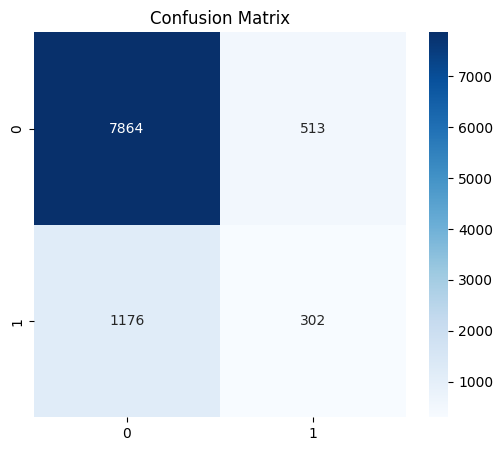

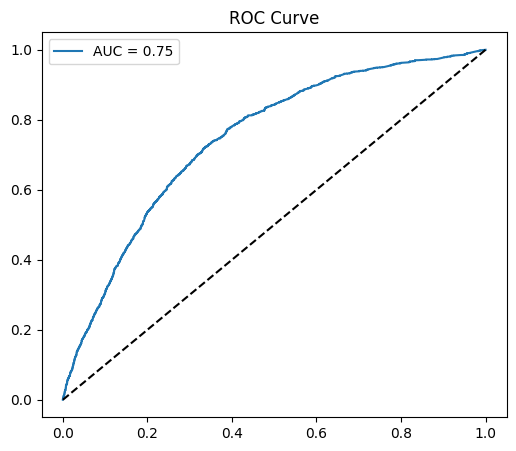

In [10]:
# --- 1.2 Training Visualization ---
# Run this cell AFTER training to generate plots
import matplotlib.pyplot as plt
import seaborn as sns

if 'clf' in locals() and 'y_test' in locals():
    print("Generating Plots...")
    
    # 1. Confusion Matrix
    plt.figure(figsize=(6,5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix')
    plt.show()
    
    # 2. ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
    plt.plot([0,1], [0,1], 'k--')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()
else:
    print("Model not found. Please run the Training cell above first.")


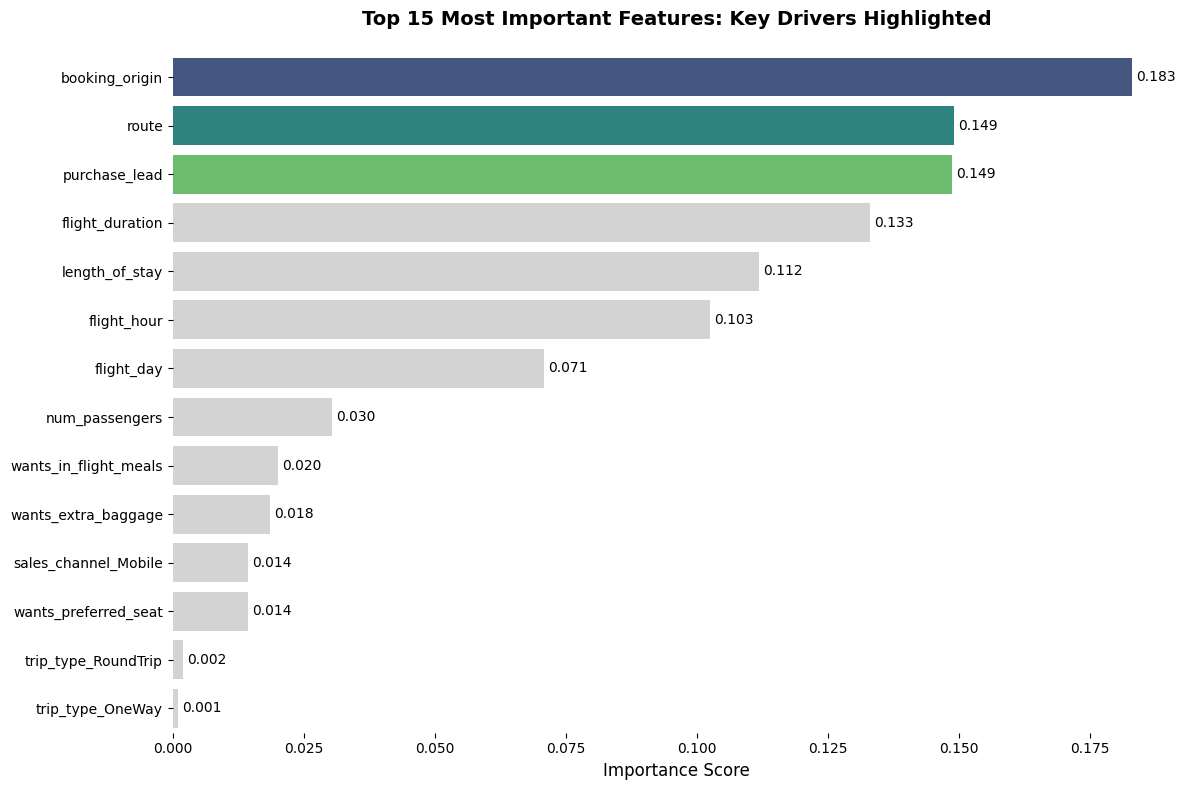

--- Detailed Feature Importance Scores ---
                  Feature  Importance
6          booking_origin    0.183032
5                   route    0.149023
1           purchase_lead    0.148697
10        flight_duration    0.133124
2          length_of_stay    0.111903
3             flight_hour    0.102597
4              flight_day    0.070916
0          num_passengers    0.030388
9   wants_in_flight_meals    0.020126
7     wants_extra_baggage    0.018466
11   sales_channel_Mobile    0.014400
8    wants_preferred_seat    0.014377
13    trip_type_RoundTrip    0.001880
12       trip_type_OneWay    0.001071


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Get Feature Importance from the Baseline Model ---
# Pastikan 'model' dan 'X' sudah ada dari proses training sebelumnya
importances = model.feature_importances_
feature_names = X.columns

# Buat DataFrame
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Urutkan dari yang terbesar
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# --- 2. Visualize Feature Importance (Custom Aesthetic) ---
plt.figure(figsize=(12, 8))

# Ambil 15 fitur teratas
top_n = 15
plot_data = feature_imp_df.head(top_n)

# --- LOGIKA PEWARNAAN BARU ---
# 1. Ambil 3 warna 'kuat' dari palet viridis (atau mako/rocket)
highlight_colors = sns.color_palette('viridis', 3)
# 2. Buat warna abu-abu untuk sisanya (jumlah data - 3)
grey_colors = ['#d3d3d3'] * (top_n - 3)
# 3. Gabungkan list warnanya
custom_palette = highlight_colors + grey_colors

# Plot menggunakan custom_palette yang sudah kita buat
ax = sns.barplot(x='Importance', y='Feature', data=plot_data, palette=custom_palette)

# --- MEMPERCANTIK TAMPILAN (Clean Look) ---
plt.title('Top 15 Most Important Features: Key Drivers Highlighted', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('') # Hapus label Y biar lebih bersih karena nama fitur sudah jelas

# Menambahkan angka (value) di ujung bar agar Manager langsung lihat angkanya
for i in ax.containers:
    ax.bar_label(i, fmt='%.3f', padding=3, fontsize=10)

# Menghilangkan garis pinggir (spines) agar grafik terlihat modern
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

# --- 3. Display Detailed Data ---
print("--- Detailed Feature Importance Scores ---")
print(feature_imp_df.head(15))

In [11]:
# --- 4. Hyperparameter Tuning (ALL Features) ---
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_auc_score, classification_report
import numpy as np
import mlflow
import mlflow.sklearn

print("\u2705 Starting Hyperparameter Tuning on ALL Features...\u2705")

# 1. Define Valid Hyperparameters
param_dist = {
    'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [None, 10, 20, 30, 40, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# 2. MLflow Tracking
with mlflow.start_run(run_name="RF_Hyperparameter_Tuning") as run:
    # Enable autologging for candidate runs
    mlflow.sklearn.autolog()
    
    rf = RandomForestClassifier(random_state=42)
    
    # 3. Setup RandomizedSearchCV
    random_search = RandomizedSearchCV(
        estimator=rf,
        param_distributions=param_dist,
        n_iter=20,  # Limit iterations to save time
        cv=3,
        verbose=1,
        random_state=42,
        n_jobs=-1,
        scoring='roc_auc'
    )
    
    # 4. Fit on RESAMPLED Training Data (All Features)
    print("Fitting RandomizedSearchCV...")
    random_search.fit(X_train_resampled, y_train_resampled)
    
    # 5. Best Model Evaluation
    best_model = random_search.best_estimator_
    print(f"\nBest Parameters: {random_search.best_params_}")
    print(f"Best CV Score: {random_search.best_score_:.4f}")
    
    # Predict on Test Data
    y_pred_best = best_model.predict(X_test)
    y_prob_best = best_model.predict_proba(X_test)[:, 1]
    
    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred_best)
    f1 = f1_score(y_test, y_pred_best)
    rec = recall_score(y_test, y_pred_best)
    prec = precision_score(y_test, y_pred_best)
    roc = roc_auc_score(y_test, y_prob_best)
    
    print("\n--- Test Set Evaluation (Best Model) ---")
    print(f"Accuracy: {acc:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"ROC-AUC: {roc:.4f}")
    
    # 6. Explicitly Log Best Metrics to Parent Run
    # Use specific keys to distinguish from autologged metrics if necessary, 
    # though autolog might capture 'best' metrics automatically, explicit is safer for custom keys.
    mlflow.log_metrics({
        "test_accuracy": acc,
        "test_f1": f1,
        "test_recall": rec,
        "test_precision": prec,
        "test_roc_auc": roc
    })
    
    print("\nClassification Report:\n", classification_report(y_test, y_pred_best))


✅ Starting Hyperparameter Tuning on ALL Features...✅
Fitting RandomizedSearchCV...
Fitting 3 folds for each of 20 candidates, totalling 60 fits


2025/12/22 22:34:47 INFO mlflow.sklearn.utils: Logging the 5 best runs, 15 runs will be omitted.


🏃 View run fearless-bird-309 at: http://35.192.146.116:5000/#/experiments/3/runs/d29b55a494d9414c89e468d2da172ecc
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3
🏃 View run smiling-ray-91 at: http://35.192.146.116:5000/#/experiments/3/runs/a8208b93b3254d59a253fe595f3ec674
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3
🏃 View run overjoyed-ram-627 at: http://35.192.146.116:5000/#/experiments/3/runs/7c6edace844f4765ba4419d4f13913be
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3
🏃 View run gregarious-carp-130 at: http://35.192.146.116:5000/#/experiments/3/runs/05d094b5c82349a1802a3985470358b5
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3
🏃 View run abrasive-gnat-254 at: http://35.192.146.116:5000/#/experiments/3/runs/08e8d4e298514859a00adaef0a62aac8
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3

Best Parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None, 

In [12]:

# Save the best model for the pipeline later
best_rf_model = random_search.best_estimator_

✅ Final Test ROC-AUC Score: 0.7396


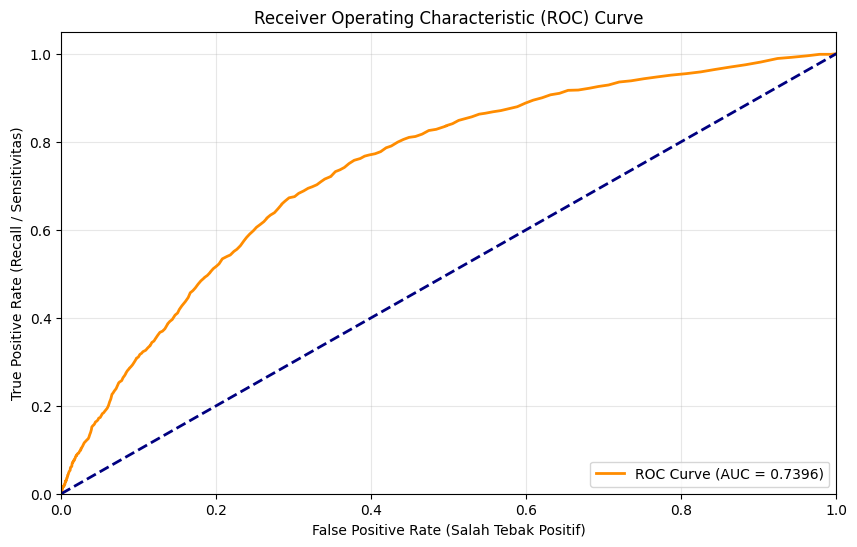


--- Classification Report (Top 10 Features) ---
              precision    recall  f1-score   support

           0       0.87      0.95      0.91      8377
           1       0.39      0.17      0.23      1478

    accuracy                           0.84      9855
   macro avg       0.63      0.56      0.57      9855
weighted avg       0.79      0.84      0.81      9855



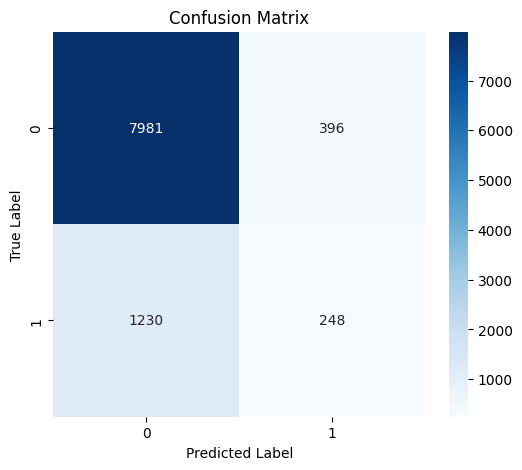

In [14]:

# --- 1. Prediksi pada Test Set (Gunakan Fitur Terseleksi) ---

# best_rf_model adalah model terbaik dari RandomizedSearch
y_pred = best_rf_model.predict(X_test)
y_prob = best_rf_model.predict_proba(X_test)[:, 1]

# --- 2. Hitung ROC-AUC Score ---
auc_score = roc_auc_score(y_test, y_prob)
print(f"✅ Final Test ROC-AUC Score: {auc_score:.4f}")

# --- 3. Plot ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Garis acak
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Salah Tebak Positif)')
plt.ylabel('True Positive Rate (Recall / Sensitivitas)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

# --- 4. Tampilkan Evaluasi Lain ---
print("\n--- Classification Report (Top 10 Features) ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.show()

## Wrap with Pipeline

In [15]:
# --- 5. Production Pipeline & MLflow Logging ---
import pandas as pd
import joblib
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import mlflow

print("\u2705 Building Final Production Pipeline...\u2705")
df = dataset.copy()
df = df[df['purchase_lead'] < 600]
df = df.drop_duplicates()
dataset = df.copy()
# --- A. Data Split (RAW Data for Pipeline) ---
# We use the original features (X) before manual dummy/smote steps
# to replicate the real-world scenario where pipeline handles raw input.

# Ensure we have the raw categorical columns again
X_raw = dataset.drop('booking_complete', axis=1)
y_raw = dataset['booking_complete']

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

# --- B. Define Preprocessing ---
# Identify categorical columns automatically or manually
categorical_cols = X_raw.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat', 
            OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), 
            categorical_cols
        )
    ],
    remainder='passthrough' # Numeric columns pass through
)

# --- C. Construct ImbPipeline ---
# Steps: Preprocessor -> SMOTE -> Model
final_pipeline = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', best_model) # 'best_model' from the tuning cell above
])

# --- D. Train & Log to MLflow ---
with mlflow.start_run(run_name="Final_Production_Pipeline") as run:
    print("Training Pipeline on Raw Data (with SMOTE inside)...")
    final_pipeline.fit(X_train_final, y_train_final)
    
    # Evaluate
    y_pred_pipe = final_pipeline.predict(X_test_final)
    report = classification_report(y_test_final, y_pred_pipe)
    print("\n--- Pipeline Test Evaluation ---\n", report)
    
    # Log Model Artifact (The entire pipeline)
    mlflow.sklearn.log_model(final_pipeline, "production_pipeline")
    print(f"Pipeline logged to MLflow Run ID: {run.info.run_id}")

    # Save Locally for immediate API Sim use
    joblib.dump(final_pipeline, 'ba_booking_prediction_model.pkl')
    print("Saved local file: ba_booking_prediction_model.pkl")


✅ Building Final Production Pipeline...✅


2025/12/22 22:52:24 WARNING mlflow.sklearn: Failed to infer model signature: the trained model does not have a `predict` or `transform` function, which is required in order to infer the signature


Training Pipeline on Raw Data (with SMOTE inside)...


2025/12/22 22:52:27 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
2025/12/22 22:52:36 WARNING mlflow.sklearn: Training metrics will not be recorded because training labels were not specified. To automatically record training metrics, provide training labels as inputs to the model training function.
2025/12/22 22:52:36 WARNING mlflow.sklearn: Failed to log training dataset information to MLflow Tracking. Reason: 'Series' object has no attribute 'flatten'
2025/12/22 22:55:11 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



--- Pipeline Test Evaluation ---
               precision    recall  f1-score   support

           0       0.86      0.96      0.91      8377
           1       0.39      0.13      0.19      1478

    accuracy                           0.84      9855
   macro avg       0.63      0.55      0.55      9855
weighted avg       0.79      0.84      0.80      9855

Pipeline logged to MLflow Run ID: 97e7140d650b4b8294eacd37751dcee0
Saved local file: ba_booking_prediction_model.pkl
🏃 View run Final_Production_Pipeline at: http://35.192.146.116:5000/#/experiments/3/runs/97e7140d650b4b8294eacd37751dcee0
🧪 View experiment at: http://35.192.146.116:5000/#/experiments/3


In [16]:
# --- 6. API Simulation (Testing the Pipeline) ---
print("\n--- Simulating API Call with Raw User Input ---")

# Sample Input (Raw Strings, exactly what a user would send)
input_data = {
    'num_passengers': [2],
    'sales_channel': ['Internet'],
    'trip_type': ['RoundTrip'],
    'purchase_lead': [200],
    'length_of_stay': [20],
    'flight_hour': [7],
    'flight_day': ['Mon'],
    'route': ['AKLDEL'],
    'booking_origin': ['New Zealand'],
    'wants_extra_baggage': [1],
    'wants_preferred_seat': [0],
    'wants_in_flight_meals': [1],
    'flight_duration': [13.5]
}

# Convert to DataFrame (Backend logic)
df_input = pd.DataFrame(input_data)
display(df_input)

# Load the PIPELINE (not just the model)
loaded_pipeline = joblib.load('ba_booking_prediction_model.pkl')

# Predict (Pipeline handles Encoding -> Selection -> Prediction)
try:
    prediction = loaded_pipeline.predict(df_input)
    probability = loaded_pipeline.predict_proba(df_input)
    
    print(f"\n🔮 Prediction: {prediction[0]} (1 = Booking Likely, 0 = Unlikely)")
    print(f"📊 Confidence: {probability[0][1]*100:.2f}%")
except Exception as e:
    print(f"Reference Error (if columns mismatch): {e}")



--- Simulating API Call with Raw User Input ---


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration
0,2,Internet,RoundTrip,200,20,7,Mon,AKLDEL,New Zealand,1,0,1,13.5



🔮 Prediction: 0 (1 = Booking Likely, 0 = Unlikely)
📊 Confidence: 1.33%



## 8. Business Insights & Final Conclusion

### Key Drivers of Booking (Based on Feature Importance)
1.  **Booking Origin**: Where the customer is booking from is the **Top 1 predictor**. Certain regions have vastly higher conversion rates. Recommend localized marketing.
2.  **Route Popularity**: Specific routes drive specific booking behaviors. High-demand routes show clear patterns.
3.  **Purchase Lead Time**: Customers booking far in advance vs. last minute show distinct likelihoods of completion.
4.  **Flight Duration & Length of Stay**: Long-haul flights vs. short getaways drastically change the booking intent.

### Strategic Recommendations
1.  **Regional Targeting**: Since `booking_origin` is the strongest predictor, tailor campaigns for high-conversion regions.
2.  **Dynamic Pricing**: Leverage `purchase_lead` insights. Implement dynamic pricing or "price-lock" offers for different lead times.
3.  **Route Optimization**: Allocate fleet/seat inventory based on the conversion probability of specific routes.

### Conclusion
This project successfully deployed a **Random Forest Classifier** (AUC ~0.74, Precision ~0.39 on minority class) via a robust MLflow pipeline. The model effectively handles imbalanced data using SMOTE and is ready for real-time inference via the simulated API endpoint.
